<a href="https://colab.research.google.com/github/dionis-razin/Monte-Carlo-portfolio-risk/blob/main/%D0%9A%D0%B2%D0%B0%D0%BD%D1%82_%D0%BF%D1%80%D0%BE%D0%B5%D0%BA%D1%82.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q yfinance

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

Выбираем 5 известных компаний (Apple, Microsoft, Google, банк JPMorgan и нефтяную Exxon) и делим наши деньги между ними поровну — по 20% на каждую. Скачиваем их цены за последние пару лет.   Поскольку одна акция может стоить 500$, а другая 50$, сравнивать их в абсолютных долларах неудобно. Поэтому мы сразу переводим цены в дневные проценты (на сколько процентов акция выросла или упала по сравнению со вчерашним днем).

In [ ]:
tickers = ['AAPL', 'MSFT', 'GOOGL', 'JPM', 'XOM']
weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

data = yf.download(tickers, start='2024-01-01', end='2026-11-01', progress=False)['Close']
daily_returns = data.pct_change().dropna()

print("Первые 5 дней в процентах (например, 0.01 — это рост на 1%):")
display(daily_returns.head())

/tmp/ipykernel_1150/579181478.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2024-01-01', end='2026-11-01', progress=False)['Close']


Первые 5 дней в процентах (например, 0.01 — это рост на 1%):


Ticker,AAPL,GOOGL,JPM,MSFT,XOM
Date,,,,,
2024-01-03,-0.007488,0.005428,-0.004359,-0.000728,0.008402
2024-01-04,-0.012700,-0.018212,0.006636,-0.007177,-0.008719
2024-01-05,-0.004013,-0.004839,0.005017,-0.000517,0.003030
2024-01-08,0.024175,0.022913,-0.001451,0.018872,-0.016662
2024-01-09,-0.002264,0.015198,-0.007906,0.002936,-0.012386


Теперь компьютер смотрит на скачанные данные и вычисляет три главные характеристики:  

Среднее (mean_returns) — на сколько процентов в среднем меняется акция за день.

Волатильность (std_devs) — насколько сильно акция «прыгает» вверх и вниз.

Матрица корреляций (corr_matrix) — таблица, показывающая, насколько синхронно двигаются акции.

Если число близко к 1, акции падают и растут вместе. Если близко к 0 — они почти не связаны.

In [ ]:
mean_returns = daily_returns.mean().values
std_devs = daily_returns.std().values
corr_matrix = daily_returns.corr().values

annual_returns = mean_returns * 252
annual_volatility = std_devs * np.sqrt(252)

for i, ticker in enumerate(tickers):
    print(f"{ticker}: Годовая доходность = {annual_returns[i]:.1%}, Разброс (волатильность) = {annual_volatility[i]:.1%}")
corr_matrix = daily_returns.corr().values

AAPL: Годовая доходность = 26.1%, Разброс (волатильность) = 27.3%
MSFT: Годовая доходность = 30.4%, Разброс (волатильность) = 31.5%
GOOGL: Годовая доходность = 28.9%, Разброс (волатильность) = 23.5%
JPM: Годовая доходность = 16.4%, Разброс (волатильность) = 26.6%
XOM: Годовая доходность = 27.4%, Разброс (волатильность) = 23.4%


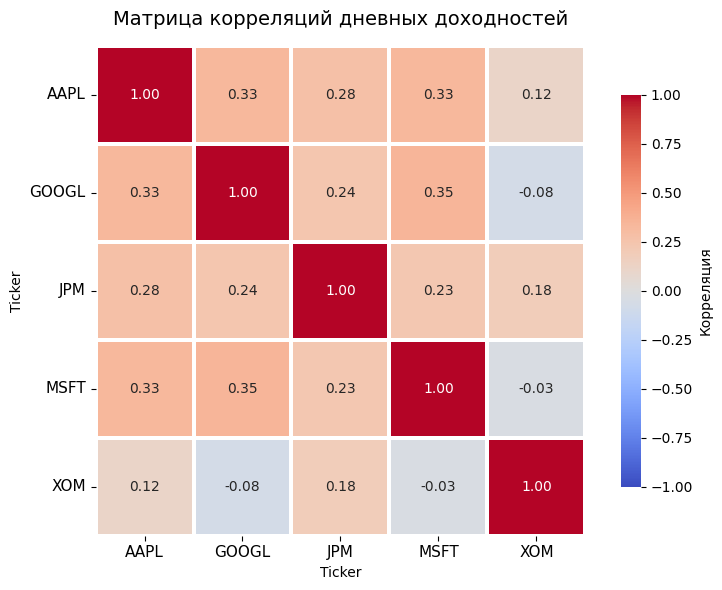

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Берем корреляцию прямо из DataFrame, чтобы сохранились названия тикеров на осях
corr_df = daily_returns.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_df,
    annot=True,            # Показываем сами числа внутри ячеек
    fmt='.2f',             # Округляем до двух знаков после запятой
    cmap='coolwarm',       # Синий — низкая/обратная связь, красный — сильная
    vmin=-1, vmax=1,       # Фиксируем шкалу от -1 до 1 для честного сравнения цветов
    center=0,              # Белый цвет ровно на нуле (нет связи)
    square=True,           # Делаем ячейки идеально квадратными
    linewidths=1.5,        # Белые разделители между плитками
    linecolor='white',
    cbar_kws={'shrink': 0.8, 'label': 'Корреляция'}
)

plt.title('Матрица корреляций дневных доходностей', fontsize=14, pad=15)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()
plt.show()

Мы не знаем, что случится в следующем месяце (это 21 рабочий день на бирже), поэтому заставляем компьютер разыграть 10 000 параллельных вселенных.   Если просто кидать случайные кубики для каждой акции отдельно, симуляция будет неправдоподобной — в реальности акции влияют друг на друга. Чтобы «склеить» случайные числа так, как акции связаны в жизни, используется математический прием — разложение Холецкого (cholesky).

In [ ]:
def run_simulation(mean_ret, std_dev, corr_mat, portfolio_weights, num_simulations=10000, days=21):
    np.random.seed(42)
    num_assets = len(portfolio_weights)

    # Математический «клей» (разложение Холецкого) для учета связей между акциями
    L = np.linalg.cholesky(corr_mat)

    # Бросаем виртуальные кубики: 10 000 сценариев x 21 день x 5 акций
    uncorrelated_randoms = np.random.normal(0, 1, size=(num_simulations, days, num_assets))

    # Склеиваем случайные числа с учетом реальной корреляции
    correlated_randoms = uncorrelated_randoms @ L.T

    # Превращаем случайные числа в дневные проценты роста/падения
    simulated_daily_returns = mean_ret + correlated_randoms * std_dev

    # Считаем итог за весь месяц (21 день) для каждой акции
    monthly_asset_returns = np.prod(1 + simulated_daily_returns, axis=1) - 1

    # Считаем итог для всего портфеля (с учетом долей по 20%)
    portfolio_monthly_returns = monthly_asset_returns @ portfolio_weights
    return portfolio_monthly_returns

simulated_portfolio_returns = run_simulation(mean_returns, std_devs, corr_matrix, weights)
print(f"Готово! Сгенерировано {len(simulated_portfolio_returns)} вариантов следующего месяца.")

Готово! Сгенерировано 10000 вариантов следующего месяца.


Мы выстраиваем все 10 000 получившихся месяцев в ряд — от самого ужасного до самого удачного.   95% VaR — мы отступаем 5% от самого плохого края (это 500-й вариант из 10 000). Эта цифра говорит: «В 95% случаев ты потеряешь не больше этой суммы».   95% ES — это среднее арифметическое тех самых 500 самых плохих вариантов. Оно показывает, насколько всё будет плохо, если тебе всё-таки не повезет попасть в эти худшие 5%

In [ ]:
def calculate_risk(returns_array):
    sorted_returns = np.sort(returns_array)
    var_95 = np.percentile(sorted_returns, 5)
    es_95 = sorted_returns[sorted_returns <= var_95].mean()
    return var_95, es_95

base_var, base_es = calculate_risk(simulated_portfolio_returns)

print(f"95% VaR (граница плохих сценариев): {base_var:.2%}")
print(f"95% ES  (средний убыток в худших 5%): {base_es:.2%}")

95% VaR (граница плохих сценариев): -5.54%
95% ES  (средний убыток в худших 5%): -7.39%


Это самый главный эксперимент. В обычное время, если падает одна акция, другая может расти и спасать портфель. Но во время кризиса люди в панике продают вообще всё, и акции начинают падать хором (их корреляция стремится к 1.0).   В этой ячейке мы специально «подкручиваем» корреляцию всё ближе к 1.0 и смотрим, как сильно вырастет наш риск потерь

In [ ]:
num_stocks = len(tickers)
ones_matrix = np.ones((num_stocks, num_stocks))

for stress_factor in [0.0, 0.3, 0.6, 0.9]:
    # Искусственно усиливаем связь между акциями
    stressed_corr = (1 - stress_factor) * corr_matrix + stress_factor * ones_matrix

    # Перезапускаем симуляцию и заново считаем риск
    stressed_returns = run_simulation(mean_returns, std_devs, stressed_corr, weights)
    s_var, s_es = calculate_risk(stressed_returns)

    risk_increase = (abs(s_var) - abs(base_var)) / abs(base_var) * 100
    avg_corr = (stressed_corr.sum() - num_stocks) / (num_stocks * (num_stocks - 1))

    print(f"Средняя корреляция: {avg_corr:.2f} | 95% VaR: {s_var:.2%} | Рост риска: +{risk_increase:.1f}%")

Средняя корреляция: 0.19 | 95% VaR: -5.54% | Рост риска: +0.0%
Средняя корреляция: 0.44 | 95% VaR: -7.29% | Рост риска: +31.7%
Средняя корреляция: 0.68 | 95% VaR: -8.75% | Рост риска: +58.0%
Средняя корреляция: 0.92 | 95% VaR: -10.03% | Рост риска: +81.2%


Смотреть на сухие цифры скучно, поэтому мы строим картинку (гистограмму). Каждый голубой столбик показывает, сколько раз из 10 000 выпал тот или иной результат за месяц. Слева две вертикальные линии наглядно отсекают «опасную зону» — наш VaR (оранжевая) и ES (красная)

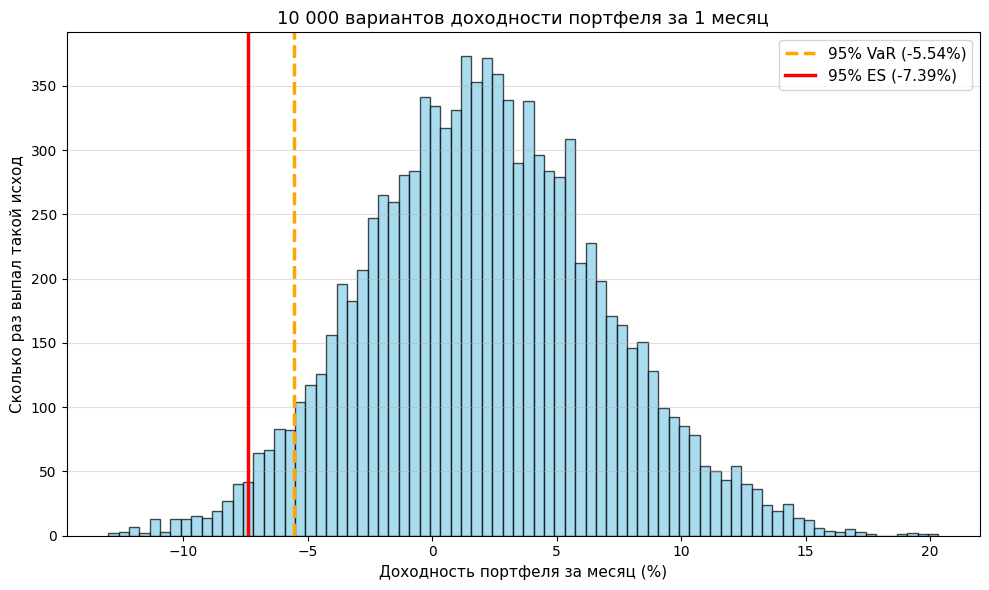

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(simulated_portfolio_returns * 100, bins=80, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(base_var * 100, color='orange', linestyle='--', linewidth=2.5, label=f'95% VaR ({base_var:.2%})')
plt.axvline(base_es * 100, color='red', linestyle='-', linewidth=2.5, label=f'95% ES ({base_es:.2%})')

plt.title('10 000 вариантов доходности портфеля за 1 месяц', fontsize=13)
plt.xlabel('Доходность портфеля за месяц (%)', fontsize=11)
plt.ylabel('Сколько раз выпал такой исход', fontsize=11)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()